# Streams extraction using deep learning
* 🔬 Data Science
* 🥠 Deep Learning and Pixel Classification

## Table of Contents
* [Introduction](#Introduction)
* [Necessary imports](#Necessary-imports)
* [Connect to your GIS](#Connect-to-your-GIS)
* [Get the data for analysis](#Get-the-data-for-analysis)
* [Export training data](#Export-training-data)
* [Prepare data](#Prepare-data)
* [Visualize a few samples from your training data](#Visualize-a-few-samples-from-your-training-data)
* [Train the model](#Train-the-model)
 * [Load model architecture](#Load-model-architecture)
 * [Find an optimal learning rate](#Find-an-optimal-learning-rate)
 * [Fit the model](#Fit-the-model)
 * [Accuracy Assessment](#Accuracy-Assessment)
 * [Visualize results in validation set](#Visualize-results-in-validation-set)
 * [Save the model](#Save-the-model)
* [Model inference](#Model-inference)
* [Conclusion](#Conclusion)

## Introduction

In this notebook, we will use 3 different geo-morphological characteristics derived from a 5 m resolution DEM in one of the watersheds of Alaska to extract streams. These 3 characteristics are Topographic position index derived from 3 cells, Geomorphon landform, and topographic wetness index.

We created a composite out of these 3 characteristic rasters and used Export raster tool to convert scale the pixels values to 8 bit unsigned. Subsequently, the images are exported as "Classified Tiles" to train a Multi-Task Road Extractor model provided by ArcGIS API for Python for extracting the streams.

Before proceeding through this notebook, it is advised to go through the API Reference for [Multi-Task Road Extractor](https://developers.arcgis.com/python/api-reference/arcgis.learn.toc.html#multitaskroadextractor). It will help in understanding the Multi-Task Road Extractor's workflow in detail.

## Necessary imports

In [1]:
import os
import zipfile
from pathlib import Path

from arcgis.gis import GIS
from arcgis.learn import prepare_data, MultiTaskRoadExtractor, ConnectNet

## Connect to your GIS

In [2]:
gis = GIS("home")

## Get the data for analysis

Here is the composite with 3 bands representing the 3 geo-morphological characteristics namely Topographic position index, Geomorphon landform, and Topographic wetness index.

<Item title:"composite_3bands_6BC_8BC_8bitunsigned" type:Tiled Imagery Layer owner:api_data_owner>
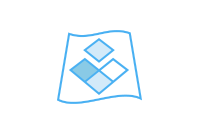

In [3]:
composite_raster = gis.content.get('6323857007ec4500bdc4ed203e19e608')
composite_raster

<Item title:"BeaverCreek_Flowlines" type:Feature Layer Collection owner:api_data_owner>
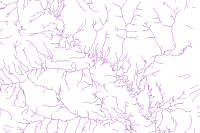

In [4]:
BeaverCreek_Flowlines = gis.content.get('53c2c22e12dc455aac821b3d7deb60b4')
BeaverCreek_Flowlines

## Export training data


Export training data using 'Export Training data for deep learning' tool, [click here](https://pro.arcgis.com/en/pro-app/tool-reference/image-analyst/export-training-data-for-deep-learning.htm) for detailed documentation: 

- Set 'composite_3bands_6BC_8BC_8bitunsigned' as `Input Raster`.
- Set a location where you want to export the training data in `Output Folder` parameter, it can be an existing folder or the tool will create that for you.
- Set the 'BeaverCreek_Flowlines' as input to the `Input Feature Class Or Classified Raster` parameter.
- Set `Class Field Value` as 'FClass'.
- Set `Image Format` as 'TIFF format'
- `Tile Size X` & `Tile Size Y` can be set to 256.
- `Stride X` & `Stride Y` can be set to 128. 
- Select 'Classified Tiles' as the `Meta Data Format`.
- In 'Environments' tab set an optimum `Cell Size`. For this example, as we have performing the analysis on the geo-morphological characteristics with 5 m resolution, so, we used '5' as the cell size.

<img src="data:image/PNG; base64, ...">


`arcpy.ia.ExportTrainingDataForDeepLearning("composite_3bands_6BC_8BC_8bitunsigned.tif", r"D:\Stream Extraction\Exported_3bands_composite_8bit_unsigned", "BeaverCreek_Flowlines", "TIFF", 256, 256, 128, 128, "ONLY_TILES_WITH_FEATURES", "Classified_Tiles", 0, "FClass", 5, None, 0, "MAP_SPACE", "PROCESS_AS_MOSAICKED_IMAGE", "NO_BLACKEN", "FIXED_SIZE")`

Alternatively, we have provided a subset of training data containing a few samples. You can use the data directly to run the experiments.

<Item title:"streams_extraction_using_connectnet" type:Image Collection owner:api_data_owner>
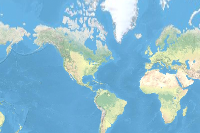

In [5]:
training_data = gis.content.get('3a95fd7a25d54898bddabf1989eea87d')
training_data

In [6]:
filepath = training_data.download(file_name=training_data.name)

In [7]:
with zipfile.ZipFile(filepath, 'r') as zip_ref:
    zip_ref.extractall(Path(filepath).parent)

In [8]:
output_path = Path(os.path.join(os.path.splitext(filepath)[0]))

## Prepare data

We will specify the path to our training data and a few hyperparameters.

- `path`: path of the folder containing training data.
- `batch_size`: Number of images your model will train on each step inside an epoch, it directly depends on the memory of your graphic card. 8 worked for us on a 11GB GPU.

In [9]:
data = prepare_data(output_path, chip_size=512, batch_size=4)

## Visualize a few samples from your training data

To get a sense of what the training data looks like, `arcgis.learn.show_batch()` method randomly picks a few training chips and visualizes them.
- `rows`: number of rows we want to see the results for.

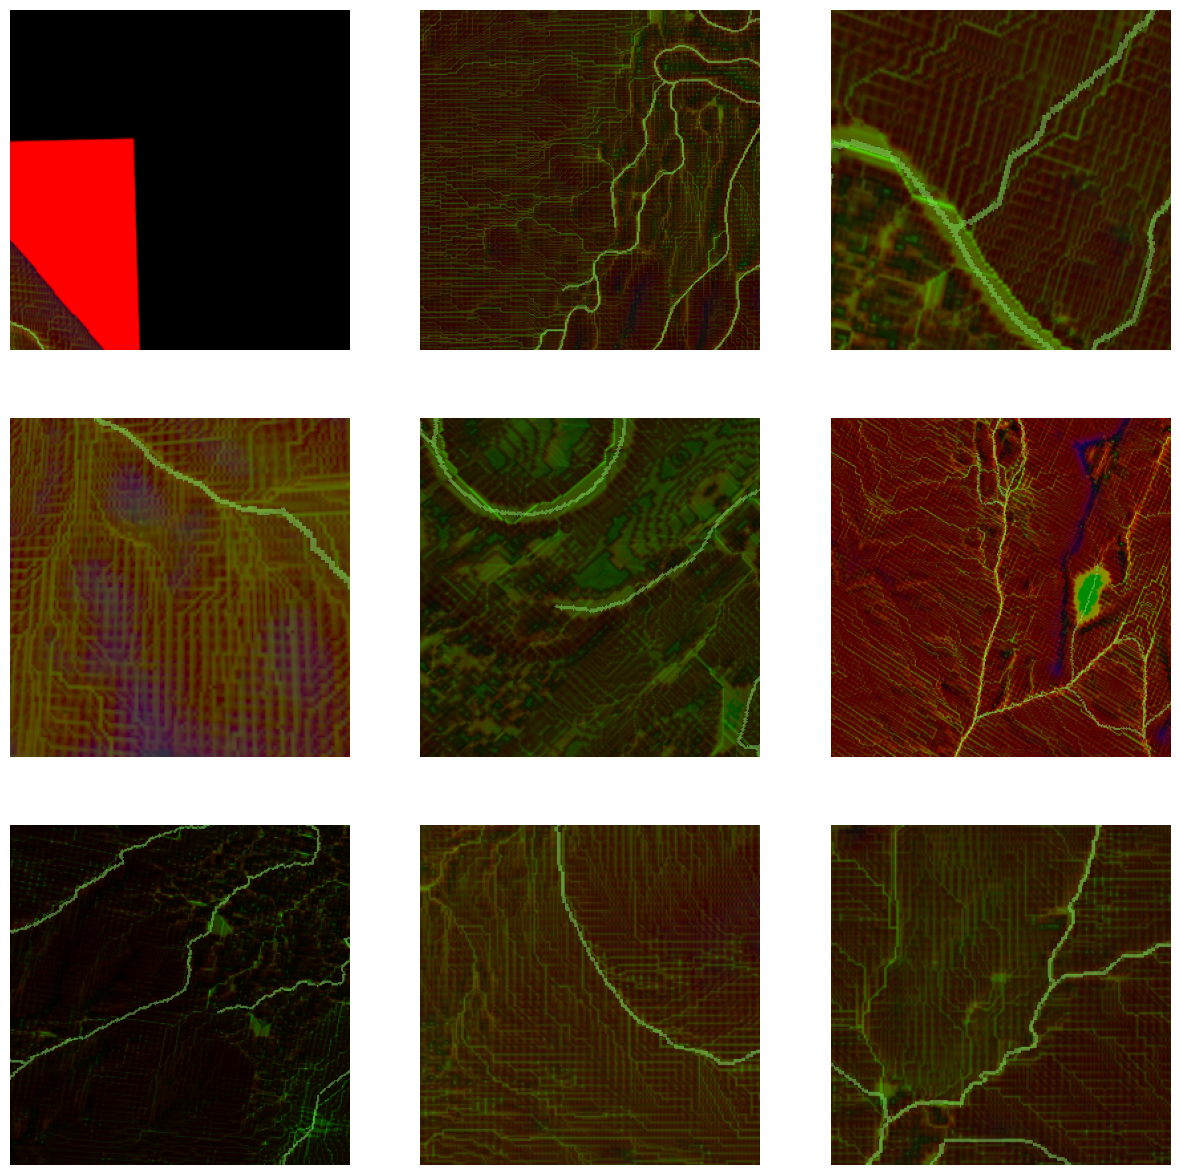

In [10]:
data.show_batch()

## Train the model

### Load model architecture

`arcgis.learn` provides the MultiTaskRoadExtractor model for classifying linear features, which is based on multi-task learning mechanism. More details about multi-task learning can be found [here](https://developers.arcgis.com/python/guide/how-multi-task-road-extractor-works/#Multi-Task-learning).

In [11]:
model = ConnectNet(data, mtl_model="hourglass")

### Find an optimal learning rate

Learning rate is one of the most important hyperparameters in model training. Here, we explore a range of learning rate to guide us to choose the best one. We will use the `lr_find()` method to find an optimum learning rate at which we can train a robust model.

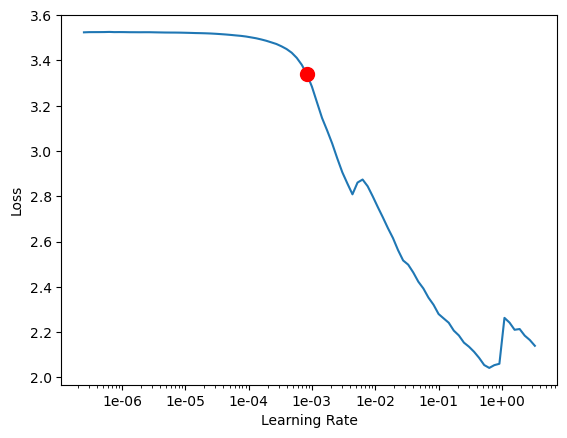

In [12]:
lr=model.lr_find()

### Fit the model

To train the model, we use the `fit()` method. To start, we will train our model for 50 epochs. Epoch defines how many times model is exposed to entire training set. We have passes three parameters to `fit()` method:
- `epochs`: Number of cycles of training on the data.
- `lr`: Learning rate to be used for training the model.
- `wd`: Weight decay to be used.

In [13]:
model.fit(50, lr)

epoch,train_loss,valid_loss,accuracy,miou,dice,time
0,0.632394,0.622243,0.831117,0.415558,0.000000,09:31
1,0.523310,0.540622,0.921272,0.767462,0.732915,09:27
2,0.460495,0.477187,0.933677,0.801455,0.773366,09:31
3,0.367851,0.450820,0.920820,0.781137,0.762663,09:45
4,0.332831,0.402109,0.934246,0.798507,0.768905,09:28
5,0.310377,0.388170,0.934500,0.810421,0.787407,09:25
6,0.302640,0.525472,0.903933,0.752356,0.736639,09:11
7,0.287657,0.379396,0.937387,0.815219,0.794576,08:51
8,0.277436,0.321924,0.952717,0.848544,0.826755,09:08
9,0.255621,0.310445,0.957915,0.860929,0.826572,09:28


As you can see, both the losses (valid_loss and train_loss) started from a higher value and ended up to a lower value, that tells our model has learnt well. Let us do an accuracy assessment to validate our observation.

### Accuracy Assessment

We can compute the mIOU (Mean Intersection Over Union) for the model we just trained in order to do the accuracy assessment. We can compute the mIOU by calling `model.mIOU`. It takes the following parameters:
- `mean`: If False returns class-wise mean IOU, otherwise returns mean IOU of all classes combined.

In [14]:
model.mIOU()

{'0': 0.9946838165542006, 1: 0.9746457531148588}

The model has a mean IOU of 0.97 which proves that the model has learnt well. Let us now see it's results on validation set.

### Visualize results in validation set

The code below will pick a few random samples and show us ground truth and respective model predictions side by side. This allows us to validate the results of your model in the notebook itself. Once satisfied we can save the model and use it further in our workflow. The `model.show_results()` method can be used to display the detected streams.

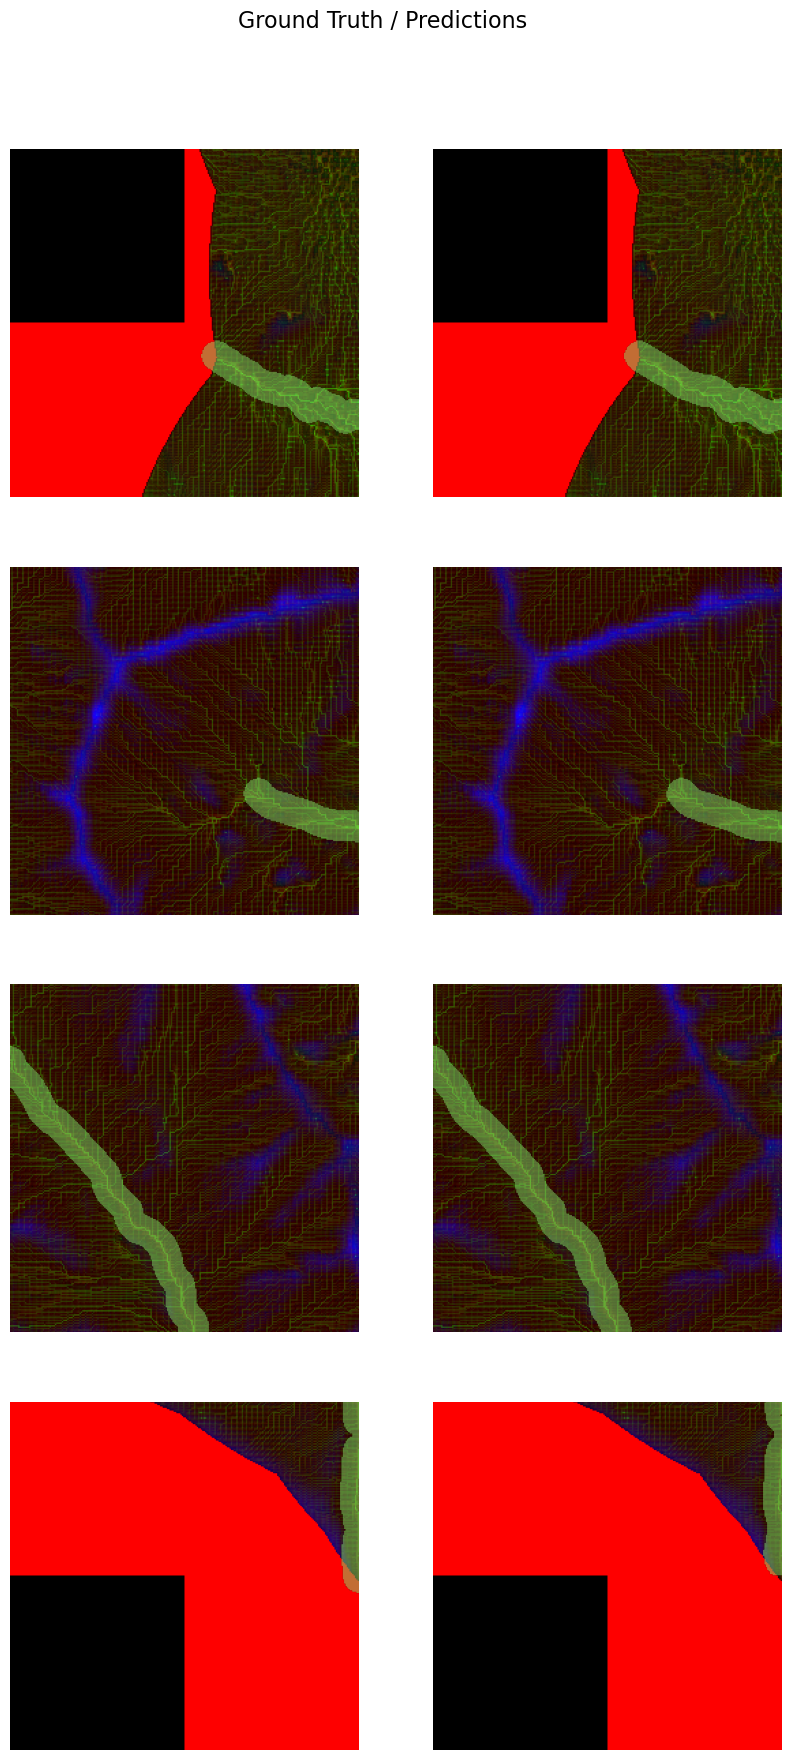

In [15]:
model.show_results(rows=4)

### Save the model

We would now save the model which we just trained as a 'Deep Learning Package' or '.dlpk' format. Deep Learning package is the standard format used to deploy deep learning models on the ArcGIS platform.

We will use the `save()` method to save the model and by default it will be saved to a folder 'models' inside our training data folder itself.

In [16]:
model.save('stream_ext_50e_2024', overwrite=True, publish=True, gis=gis)

Published DLPK Item Id: 99d8629d8ae541209efae8c41393136e


WindowsPath('~/AppData/Local/Temp/streams_extraction_using_connectnet/models/stream_ext_50e_2024')

## Model inference

The saved model can be used to classify streams using the `Classify Pixels Using Deep Learning` tool available in ArcGIS Pro, or ArcGIS Enterprise.

<img src="data:image/PNG; base64, ...">


`arcpy.ia.ClassifyPixelsUsingDeepLearning("composite_3bands_6BC_8BC_8bitunsigned.tif", r"D:/stream_ext_20e/stream_ext_20e.dlpk", "padding 64;batch_size 4;predict_background True;return_probability_raster False;threshold 0.5", "PROCESS_AS_MOSAICKED_IMAGE", None); out_classified_raster.save(r"\Documents\ArcGIS\Packages\Stream Extraction demo_9ee52d\p20\stream_identification.gdb\detected_streams")`

The output of the model is a layer of detected streams which is shown below:

<Item title:"det_streams" type:Tiled Imagery Layer owner:api_data_owner>
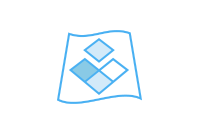

In [17]:
extracted_streams = gis.content.get('3cc376c1bed7428ba50bdf768d28a735')
extracted_streams

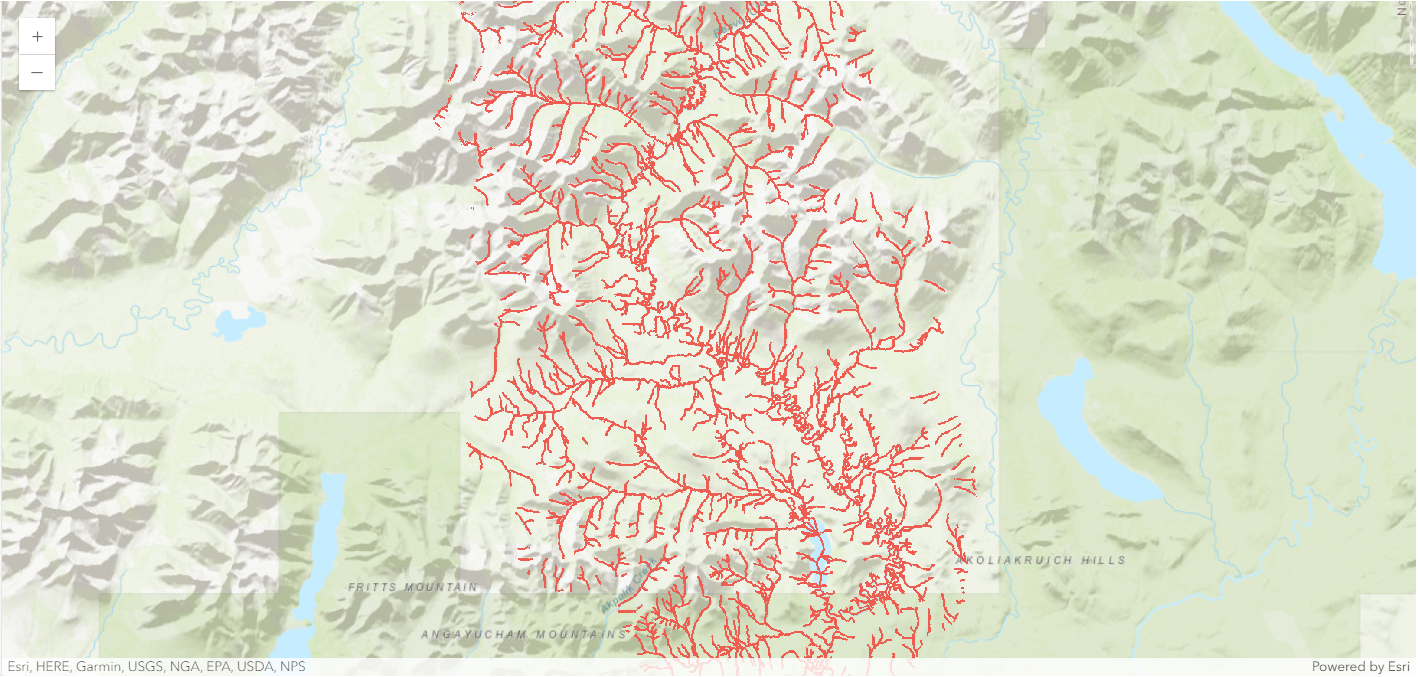

In [18]:
map1 = gis.map()
map1.content.add(extracted_streams)
map1

<image src="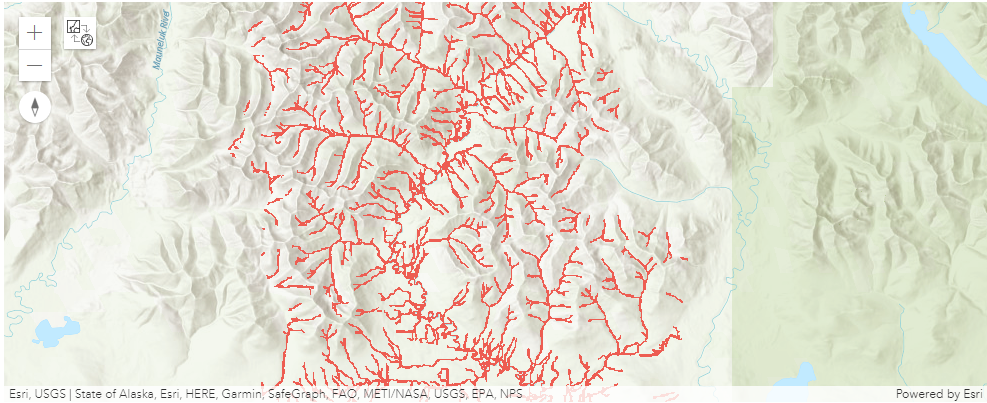">

In [19]:
map1.zoom_to_layer(extracted_streams)

## Conclusion

The notebook presents the workflow showing how easily you can combine traditional morphological landform characteristics with deep learning methodologies using `arcgis.learn` to detect streams.